# RMDS Hackathon - Dataset B: who will accept an H1N1 vaccine?

**Goal:** predict `h1n1_vaccine` for each test respondent so the town spends the least
on vaccines ($500) and hospitalisations ($25,000).

1. Setup  2. Data exploration  3. Pre-processing  4. Cost model  5. Modelling
6. Performance analysis  7. Submissions  8. Explainable AI  9. Summary



## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             precision_score, recall_score, confusion_matrix)
from sklearn.inspection import permutation_importance

# Settings
GROUP = 0
TRAIN_PATH = "dataset_B_training.csv"
TEST_PATH = "dataset_B_testing.csv"
TARGET = "h1n1_vaccine"
ID = "respondent_id"
SEED = 42
BLUE = "#3b6ea5"

# Prices from the assignment
VACCINE_COST = 500
HOSP_COST = 25_000

# Hospitalisation assumptions (explained in section 4)
BASE_P_HOSP = 0.0045    # risk for an infected, unvaccinated, healthy adult
VE_UNDER_65 = 0.62      # vaccine effectiveness, under 65
VE_65_PLUS = 0.43       # vaccine effectiveness, 65+
CHRONIC_STEP = 2.0      # each chronic condition adds 2x the base risk
CHRONIC_CAP = 3         # count at most 3 conditions
AGE_65_MULT = 2.0       # 65+ have double the risk

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (4756, 31) | test: (4749, 30)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


## 2. Data exploration

In [2]:
# Column types and basic statistics
train.info()
train.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.50,1373.08,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,1.66,0.89,0.0,1.00,2.0,2.00,3.0
h1n1_knowledge,4734.0,1.31,0.61,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4739.0,0.06,0.23,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4729.0,0.74,0.44,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4752.0,0.08,0.27,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4748.0,0.84,0.36,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4747.0,0.36,0.48,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4741.0,0.34,0.47,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4736.0,0.70,0.46,0.0,0.00,1.0,1.00,1.0


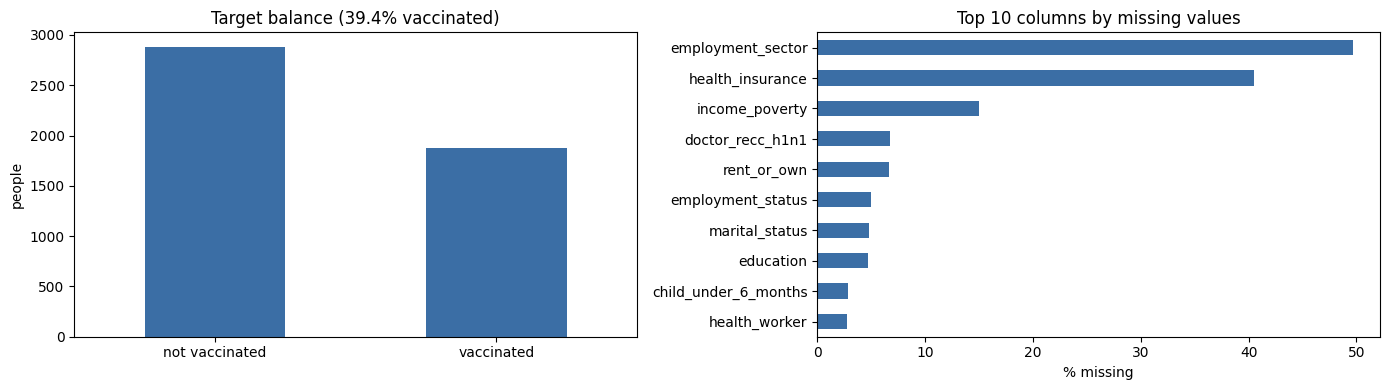

In [3]:
# Class balance and missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train[TARGET].value_counts().rename({0: "not vaccinated", 1: "vaccinated"}).plot.bar(
    ax=axes[0], color=BLUE, rot=0)
axes[0].set_title(f"Target balance ({train[TARGET].mean():.1%} vaccinated)")
axes[0].set_xlabel("")
axes[0].set_ylabel("people")

missing = (train.isna().mean() * 100).sort_values(ascending=False).head(10)
missing.sort_values().plot.barh(ax=axes[1], color=BLUE)
axes[1].set_title("Top 10 columns by missing values")
axes[1].set_xlabel("% missing")

plt.tight_layout()
plt.savefig("eda_balance_missing.png", dpi=120)
plt.show()

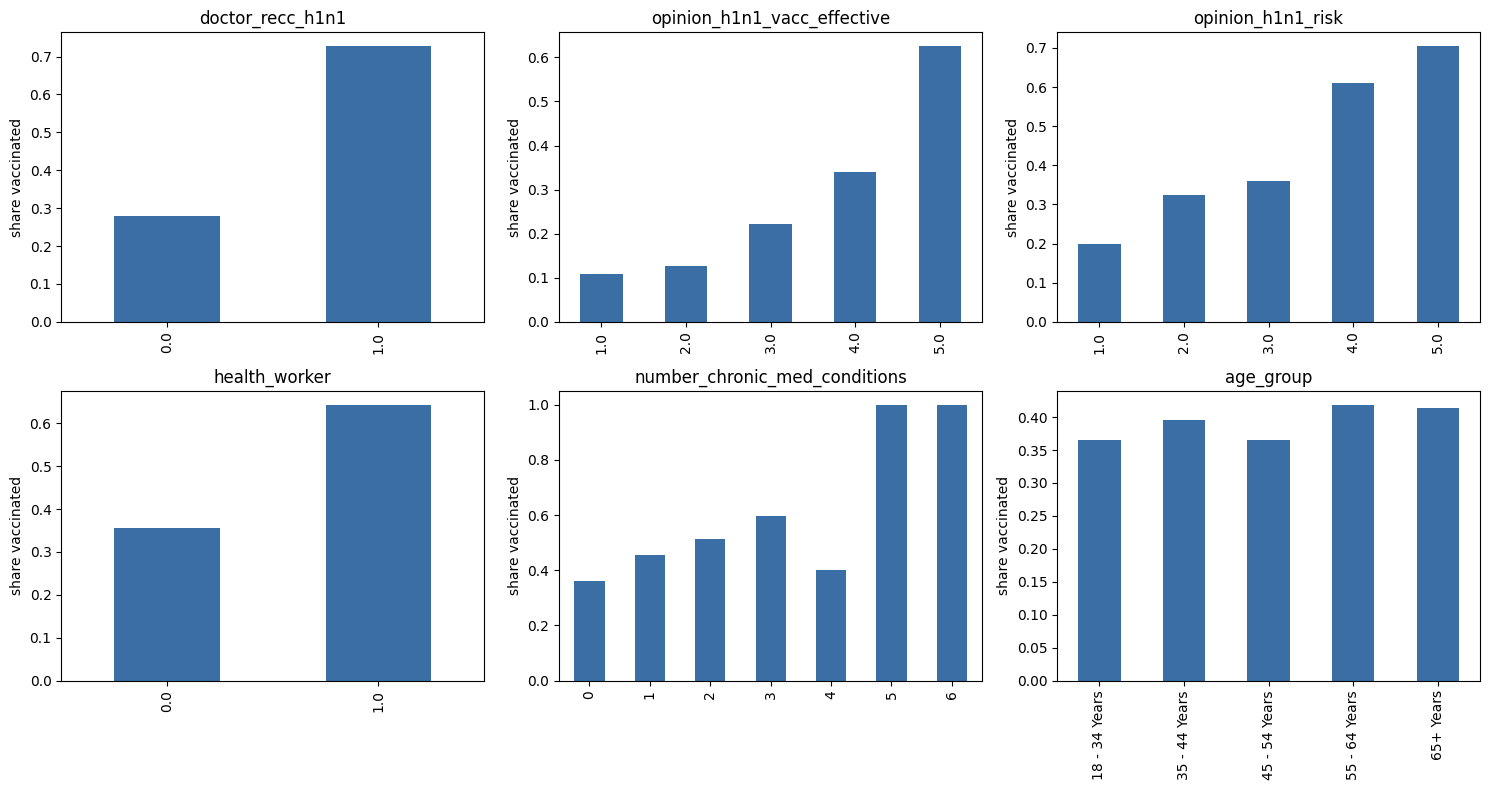

In [4]:
# Vaccination rate for each answer of six key questions
key_features = ["doctor_recc_h1n1", "opinion_h1n1_vacc_effective", "opinion_h1n1_risk",
                "health_worker", "number_chronic_med_conditions", "age_group"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_features):
    train.groupby(col)[TARGET].mean().plot.bar(ax=ax, color=BLUE)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("share vaccinated")
plt.tight_layout()
plt.savefig("eda_vaccination_rates.png", dpi=120)
plt.show()

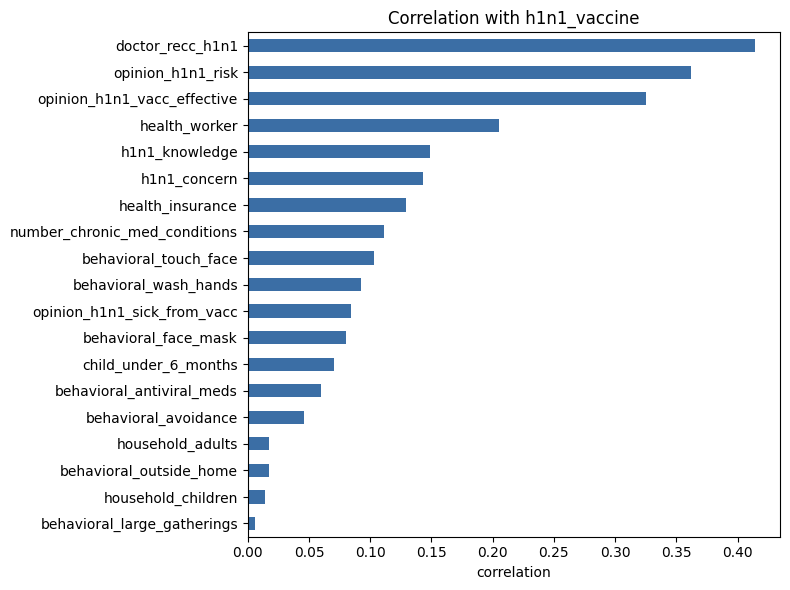

In [5]:
# Correlation of each numeric feature with the target
corr = train.drop(columns=ID).corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
corr.plot.barh(ax=ax, color=BLUE)
plt.title("Correlation with h1n1_vaccine")
plt.xlabel("correlation")
plt.tight_layout()
plt.savefig("eda_correlations.png", dpi=120)
plt.show()

**Findings**
* 39% of respondents were vaccinated, so the classes are fairly balanced.
* A doctor's recommendation, believing the vaccine works, and feeling at risk are the
  strongest signals. Health workers are also far more likely to vaccinate.
* `employment_sector` (50%) and `health_insurance` (40%) have many gaps, so we keep
  "no answer" as information instead of dropping rows.

## 3. Pre-processing
* Numeric columns: fill gaps with the median, add a "was missing" flag, rescale.
* Text columns: gaps become a "missing" category, then one-hot encoding.

In [6]:
features = [c for c in train.columns if c not in (ID, TARGET)]
cat_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
num_cols = [c for c in features if c not in cat_cols]

numeric_prep = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
categorical_prep = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_prep, num_cols),
    ("cat", categorical_prep, cat_cols),
])

X = train[features]
y = train[TARGET].to_numpy()
X_test = test[features]
print(f"{len(num_cols)} numeric and {len(cat_cols)} text features")

19 numeric and 10 text features


## 4. Cost model
Everyone gets infected (assignment rule). The bill per person:

| we send a vaccine | they want it | vaccine money | hospital risk |
|---|---|---|---|
| yes | yes | $500 | reduced by the vaccine |
| yes | no  | $500 (ruined) | full |
| no  | yes | $500 (compensation) | full |
| no  | no  | $0 | full |

**Hospitalisation probability**
* CDC: about 61 million US cases and 274,000 hospitalisations in the 2009 pandemic,
  so roughly **0.45%** of infections ended in hospital.
* Borse et al. (CDC, *Emerging Infectious Diseases*, 2013): vaccine **62%** effective
  against hospitalisation, **43%** for people 65+.
* Chronic conditions and age 65+ raise the risk (our own simple multipliers).

**Decision rule:** send a vaccine when
`P(accept) > 500 / (500 + 25000 x risk x effectiveness)`.
That is about 0.88 for a healthy adult and 0.51 for someone with three chronic conditions.

In [7]:
def hospitalisation_inputs(df):
    """Unvaccinated hospitalisation risk and vaccine effectiveness per person."""
    n_chronic = df["number_chronic_med_conditions"].clip(upper=CHRONIC_CAP)
    is_65_plus = df["age_group"].eq("65+ Years")
    risk = BASE_P_HOSP * (1 + CHRONIC_STEP * n_chronic) * np.where(is_65_plus, AGE_65_MULT, 1.0)
    effectiveness = np.where(is_65_plus, VE_65_PLUS, VE_UNDER_65)
    return risk.to_numpy(), effectiveness


def total_cost(y_true, y_pred, risk, effectiveness):
    """Total dollars paid by the town."""
    pays_vaccine = (y_pred == 1) | (y_true == 1)     # vaccine sent, or compensation owed
    protected = (y_pred == 1) & (y_true == 1)        # vaccine sent and used
    hosp_risk = risk * np.where(protected, 1 - effectiveness, 1.0)
    return float((VACCINE_COST * pays_vaccine + HOSP_COST * hosp_risk).sum())


def cost_optimal_decision(p_accept, risk, effectiveness):
    """Send a vaccine only when the expected saving beats the expected waste."""
    threshold = VACCINE_COST / (VACCINE_COST + HOSP_COST * risk * effectiveness)
    return (p_accept > threshold).astype(int)


risk_train, ve_train = hospitalisation_inputs(train)
risk_test, ve_test = hospitalisation_inputs(test)

## 5. Modelling
Five models plus their average, each scored with 5-fold cross-validation
(every person is predicted by a model that never saw them).

In [8]:
models = {
    "logistic": LogisticRegression(C=0.3, max_iter=2000),
    "decision_tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=SEED),
    "knn": KNeighborsClassifier(n_neighbors=50),
    "random_forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                            n_jobs=-1, random_state=SEED),
    "boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                               max_leaf_nodes=15, l2_regularization=1.0,
                                               random_state=SEED),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_prob, test_prob = {}, {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_prob[name] = cross_val_predict(pipe, X, y, cv=folds, method="predict_proba")[:, 1]
    pipe.fit(X, y)
    test_prob[name] = pipe.predict_proba(X_test)[:, 1]
    models[name] = pipe

# Ensemble = average of the five models
cv_prob["ensemble"] = np.mean([cv_prob[m] for m in models], axis=0)
test_prob["ensemble"] = np.mean([test_prob[m] for m in models], axis=0)

## 6. Performance analysis

In [9]:
# Standard metrics at the usual 0.5 cut-off
metrics = pd.DataFrame({
    name: {
        "AUC": roc_auc_score(y, p),
        "accuracy": accuracy_score(y, p > 0.5),
        "precision": precision_score(y, p > 0.5),
        "recall": recall_score(y, p > 0.5),
    } for name, p in cv_prob.items()
}).T.round(3)
print(metrics)

                 AUC  accuracy  precision  recall
logistic       0.849     0.787      0.759   0.676
decision_tree  0.823     0.764      0.732   0.633
knn            0.830     0.769      0.792   0.562
random_forest  0.851     0.786      0.791   0.621
boosting       0.852     0.786      0.760   0.669
ensemble       0.855     0.785      0.775   0.639


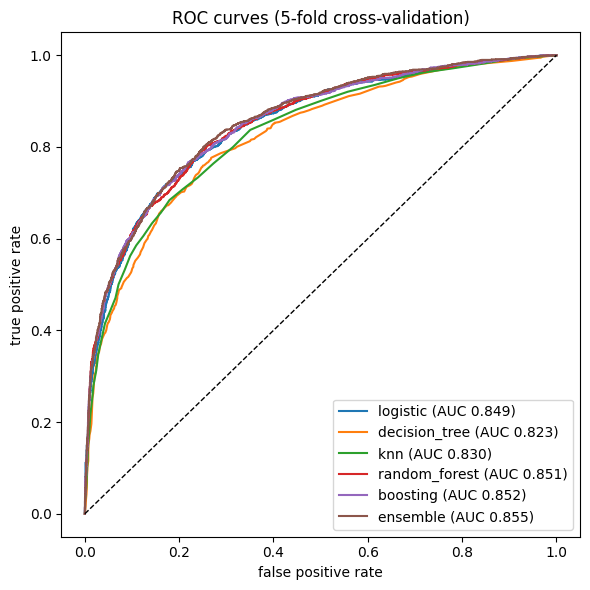

In [10]:
# ROC curves
plt.figure(figsize=(6, 6))
for name, p in cv_prob.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC curves (5-fold cross-validation)")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=120)
plt.show()

In [11]:
# The real metric: total cost of each strategy
def decide(prob, rule, risk, effectiveness):
    if rule == "cost":
        return cost_optimal_decision(prob, risk, effectiveness)
    return (prob > rule).astype(int)


strategies = {f"{name} + cost rule": (name, "cost") for name in cv_prob}
strategies["ensemble + 0.5 cut-off"] = ("ensemble", 0.5)

rows = []
for label, (name, rule) in strategies.items():
    pred = decide(cv_prob[name], rule, risk_train, ve_train)
    rows.append({"strategy": label,
                 "cost": total_cost(y, pred, risk_train, ve_train),
                 "vaccines_sent": int(pred.sum())})
results = pd.DataFrame(rows).sort_values("cost").reset_index(drop=True)
results["cost_per_person"] = (results["cost"] / len(y)).round(2)
print(results.to_string(index=False))

# Reference points
references = {
    "send to nobody": total_cost(y, np.zeros_like(y), risk_train, ve_train),
    "send to everybody": total_cost(y, np.ones_like(y), risk_train, ve_train),
    "perfect knowledge": total_cost(y, y, risk_train, ve_train),
}
print("\nReference costs:", {k: f"${v:,.0f}" for k, v in references.items()})

                 strategy       cost  vaccines_sent  cost_per_person
     boosting + cost rule 2072401.75            840           435.74
     logistic + cost rule 2080136.00            781           437.37
     ensemble + cost rule 2084039.75            568           438.19
random_forest + cost rule 2093751.50            377           440.23
decision_tree + cost rule 2098363.50            819           441.20
          knn + cost rule 2100727.75            367           441.70
   ensemble + 0.5 cut-off 2155620.50           1545           453.24

Reference costs: {'send to nobody': '$2,178,212', 'send to everybody': '$3,331,906', 'perfect knowledge': '$1,890,906'}


In [12]:
# Confusion matrix of the cheapest strategy
best_label = results.loc[0, "strategy"]
best_model, best_rule = strategies[best_label]
best_pred = decide(cv_prob[best_model], best_rule, risk_train, ve_train)
print("Best strategy:", best_label)
print(pd.DataFrame(confusion_matrix(y, best_pred),
                   index=["wants no vaccine", "wants vaccine"],
                   columns=["not sent", "sent"]))

Best strategy: boosting + cost rule
                  not sent  sent
wants no vaccine      2783    99
wants vaccine         1133   741


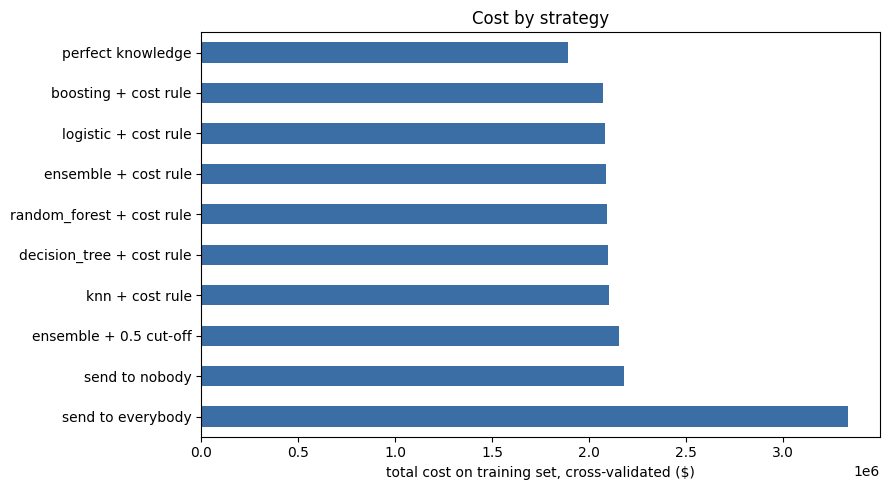

In [13]:
# Cost of every strategy and reference point
all_costs = pd.Series({**references, **results.set_index("strategy")["cost"].to_dict()})
fig, ax = plt.subplots(figsize=(9, 5))
all_costs.sort_values(ascending=False).plot.barh(ax=ax, color=BLUE)
ax.set_xlabel("total cost on training set, cross-validated ($)")
ax.set_title("Cost by strategy")
plt.tight_layout()
plt.savefig("cost_comparison.png", dpi=120)
plt.show()

In [14]:
# Sensitivity check: does the best strategy still win if our base risk is wrong?
sensitivity = []
for factor in [0.5, 1.0, 2.0, 4.0]:
    risk = risk_train * factor
    pred = decide(cv_prob[best_model], best_rule, risk, ve_train)
    sensitivity.append({
        "base risk": f"{BASE_P_HOSP * factor:.2%}",
        "best strategy": total_cost(y, pred, risk, ve_train),
        "send to nobody": total_cost(y, np.zeros_like(y), risk, ve_train),
        "vaccines_sent": int(pred.sum()),
    })
sensitivity = pd.DataFrame(sensitivity)
sensitivity["saving"] = sensitivity["send to nobody"] - sensitivity["best strategy"]
print(sensitivity.round(0).to_string(index=False))

base risk  best strategy  send to nobody  vaccines_sent   saving
    0.22%      1519281.0       1557606.0            569  38325.0
    0.45%      2072402.0       2178212.0            840 105811.0
    0.90%      3155852.0       3419425.0           1202 263573.0
    1.80%      5233699.0       5901850.0           1639 668151.0


## 7. Submissions
One file per model (all using the cost rule), ranked by cross-validated cost, in the
same format as `dataset_B_example_submission.csv`. The ensemble and the 0.5 cut-off are
kept above as comparisons only.

In [15]:
model_strategies = [s for s in results["strategy"] if strategies[s][0] in models and strategies[s][1] == "cost"]
for rank, label in enumerate(model_strategies, start=1):
    name, rule = strategies[label]
    pred = decide(test_prob[name], rule, risk_test, ve_test)
    submission = pd.DataFrame({ID: test[ID], TARGET: pred.astype(float)})
    filename = f"challenge_submission_group_{GROUP}_order_{rank}.csv"
    submission.to_csv(filename, index=False)
    print(f"{filename}: {label} -> sends {pred.sum()} of {len(pred)} vaccines")

challenge_submission_group_0_order_1.csv: boosting + cost rule -> sends 860 of 4749 vaccines
challenge_submission_group_0_order_2.csv: logistic + cost rule -> sends 786 of 4749 vaccines
challenge_submission_group_0_order_3.csv: random_forest + cost rule -> sends 420 of 4749 vaccines
challenge_submission_group_0_order_4.csv: decision_tree + cost rule -> sends 888 of 4749 vaccines
challenge_submission_group_0_order_5.csv: knn + cost rule -> sends 411 of 4749 vaccines


## 8. Explainable AI

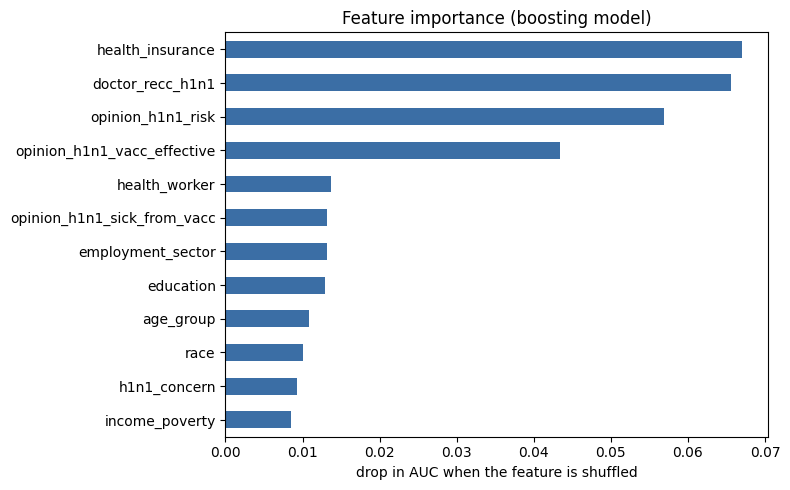

In [16]:
# Permutation importance: how much AUC drops when one feature is shuffled
importance = permutation_importance(models["boosting"], X, y, scoring="roc_auc",
                                    n_repeats=5, random_state=SEED, n_jobs=-1)
top = pd.Series(importance.importances_mean, index=features).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 5))
top.plot.barh(ax=ax, color=BLUE)
plt.title("Feature importance (boosting model)")
plt.xlabel("drop in AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=120)
plt.show()

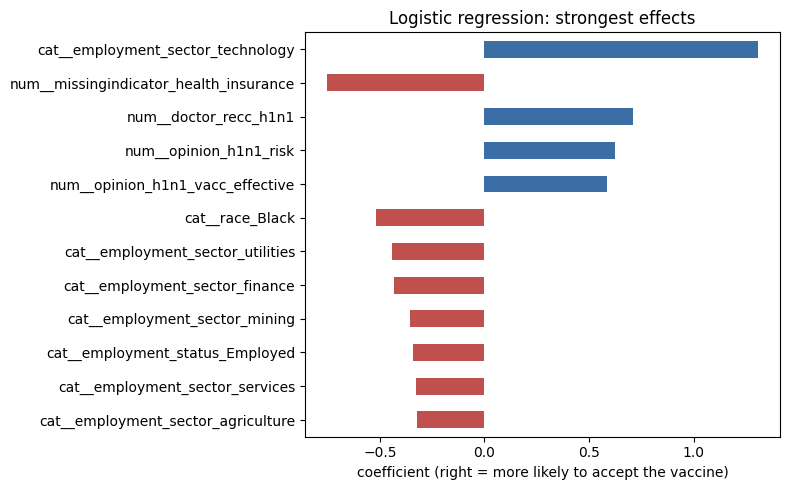

In [17]:
# Logistic regression coefficients: direction of each effect
names = models["logistic"]["prep"].get_feature_names_out()
coefs = pd.Series(models["logistic"]["model"].coef_[0], index=names)
strongest = coefs.reindex(coefs.abs().sort_values().tail(12).index)
fig, ax = plt.subplots(figsize=(8, 5))
strongest.plot.barh(ax=ax, color=np.where(strongest > 0, BLUE, "#c0504d"))
plt.title("Logistic regression: strongest effects")
plt.xlabel("coefficient (right = more likely to accept the vaccine)")
plt.tight_layout()
plt.savefig("logistic_coefficients.png", dpi=120)
plt.show()

## 9. Summary
* Five models were compared. Boosting, random forest and logistic regression rank people
  best (AUC about 0.85); the decision tree and KNN are a little weaker (0.82-0.83).
* A wasted vaccine costs $500 but an accepted one saves only about $70 in hospital costs
  for a healthy adult, so vaccines should go only to people very likely to accept.
* The per-person cost rule beats both the plain 0.5 cut-off and sending no vaccines.
* The main drivers are health insurance (including whether the question was answered),
  a doctor's recommendation, and opinions on H1N1 risk and vaccine effectiveness.
* Limitation: the hospitalisation multipliers are simple assumptions; the sensitivity
  table shows how the result changes if the base risk is different.